# Homework09

Exercises to practice unsupervised learning with clustering

## Goals

- Get more practice with the ML flow: encode -> normalize -> train -> evaluate
- Understand the tradeoffs of modeling parameters
- Develop intuition for different clustering models and when to use them

### Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework.

In [10]:
# !wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
# !wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py
# !wget -q "https://github.com/PSAM-5020-2026F-A/Homework/raw/main/html.tgz" -O html.tgz
# !tar -xzf html.tgz

# My Note: I need to use deployment for Windows device, since I prefer using VSCode, I found that Codespace has limits in usage.
# My Note: I need to use deployment for Windows device, ...
!curl -L -s -o data_utils.py "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py"
!curl -L -s -o image_utils.py "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py"

In [7]:
import json
import matplotlib.pyplot as plt
import pandas as pd

from os import listdir
from PIL import Image as PImage

from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans

from data_utils import balance_score, distance_score, silhouette_score, display_silhouette_plots
from data_utils import object_from_json_url

from image_utils import get_pixels, make_image

## Helmet Sizing

### Load Dataset

Let's load up the full [ANSUR](https://www.openlab.psu.edu/ansur2/) dataset that we looked at briefly in [Week 02](https://github.com/PSAM-5020-2026F-A/WK02) and then again in [Homework06](https://github.com/PSAM-5020-2026F-A/Homework06).

This is the dataset that has anthropometric information about U.S. Army personnel.

#### WARNING

Like we mentioned in class, this dataset is being used for these exercises due to the level of detail in the dataset and the rigorous process that was used in collecting the data.

This is a very specific dataset and should not be used to draw general conclusions about people, bodies, or anything else that is not related to the distribution of physical features of U.S. Army personnel.

In [14]:
# Load Dataset
ANSUR_FILE = "https://raw.githubusercontent.com/PSAM-5020-2026F-A/5020-utils/main/datasets/json/ansur.json"
ansur_data = object_from_json_url(ANSUR_FILE)

# Look at first 2 records
ansur_data[:2]

[{'age': 18,
  'gender': 'F',
  'height': 66,
  'weight': 135,
  'span': 1699,
  'stature': 1645,
  'ear': {'breadth': 30, 'length': 61, 'protrusion': 20},
  'foot': {'breadth': 97, 'length': 243},
  'hand': {'breadth': 78, 'length': 182, 'palm': 108},
  'head': {'height': 243, 'circumference': 557}},
 {'age': 30,
  'gender': 'M',
  'height': 68,
  'weight': 207,
  'span': 1749,
  'stature': 1715,
  'ear': {'breadth': 35, 'length': 63, 'protrusion': 17},
  'foot': {'breadth': 100, 'length': 252},
  'hand': {'breadth': 87, 'length': 184, 'palm': 114},
  'head': {'height': 238, 'circumference': 560}}]

Let's load it into a `DataFrame`, like last week.

In [15]:
# Read into DataFrame
ansur_df = pd.json_normalize(ansur_data)
ansur_df.head()

,age,gender,height,weight,span,stature,ear.breadth,ear.length,ear.protrusion,foot.breadth,foot.length,hand.breadth,hand.length,hand.palm,head.height,head.circumference
0,18,F,66,135,1699,1645,30,61,20,97,243,78,182,108,243,557
1,30,M,68,207,1749,1715,35,63,17,100,252,87,184,114,238,560
2,27,M,67,121,1684,1657,36,59,24,92,251,84,180,103,239,516
3,20,M,73,185,1878,1828,36,60,21,104,280,95,201,124,270,582
4,33,M,76,150,1977,1883,39,65,27,101,271,90,194,113,254,559


### Unsupervised Learning

Let's pretend we are designing next-generation helmets with embedded over-the-ear headphones and we want to have a few options for sizes.

We could use clustering to see if there is a number of clusters that we can divide our population into, so each size covers a similar portion of the population.

We can follow similar steps to regression to create a clustering model that uses features about head and ear sizes:

1. Load dataset (done! 🎉)
2. Encode label features as numbers
3. Normalize the data
4. Separate the feature variables we want to consider (done below)
5. Pick a clustering algorithm
6. Determine number of clusters
7. Cluster data
8. Interpret results

For step $5$, it's fine to just pick an algorithm ahead of time to see what happens, but feel free to experiment and plot results for multiple clustering methods.

In [21]:
## Encode non-numerical features

gender_encoder = OrdinalEncoder()
ansur_df["gender"] = gender_encoder.fit_transform(ansur_df[["gender"]])

## Normalize the data

ansur_scaler = StandardScaler()
ansur_scaled = ansur_scaler.fit_transform(ansur_df)
ansur_scaled_df = pd.DataFrame(ansur_scaled, columns = ansur_df.columns)


In [22]:
## Separate the features we want to consider
ansur_features = ansur_scaled_df[["head.height", "head.circumference", "ear.length", "ear.breadth", "ear.protrusion"]]

balance_score: 0.9448412698412698
silhouette_score 0.14143477457271797
distance_score: 1.3396660885516474


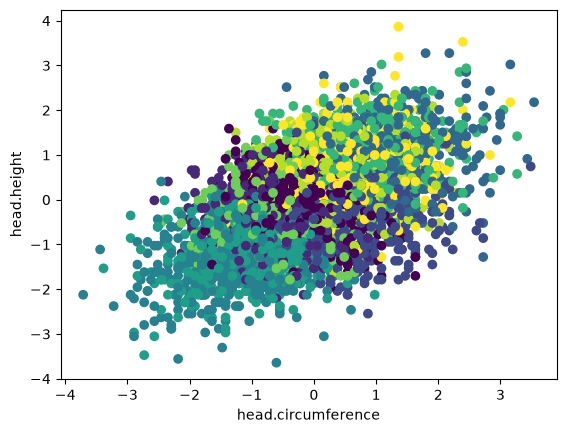

In [26]:
## Create Clustering model
km_model = KMeans(n_clusters = 10)

## Run the model(s) on the data
predicted = km_model.fit_predict(ansur_features)

## Check errors
print("balance_score:", balance_score(predicted))
print("silhouette_score", silhouette_score(ansur_features, predicted))
print("distance_score:", distance_score(ansur_features, predicted))

## Plot clusters as function of 2 or 3 variables
plt.scatter(ansur_features["head.circumference"], ansur_features["head.height"], c = predicted)
plt.xlabel("head.circumference")
plt.ylabel("head.height")
plt.show()


### Interpretation

<span style="color:hotpink;">
Which clustering algorithm did you choose?<br>
Did you try a different one?<br>
Do the clusters make sense ? Do they look balanced ?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>
<br>
Firstly I choose KMeans algorithm. Then I tried Gaussian Mixture algorithm with the same clustering number.<br>
KMeans algorithm scores are mostly higher than Gaussian Mixture scores, except the distance scores. The Gaussian Mixture Model distance score is higher.<br> 
The diagram looks balanced, we can tell clearly there are clustering groups in each color. However, there are still some overlaps / infiltration areas between clustering boundaries. <br>

balance_score: 0.903968253968254
silhouette_score 0.12052872117579962
distance_score: 1.382861570231849


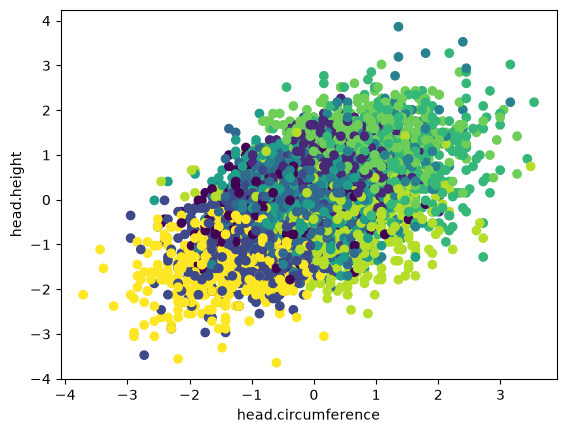

In [ ]:
# To Answer Interpretation Question 2: Try a different Clustering Model (Gaussian Mixture)
GaussianMixture_model = GaussianMixture(n_components = 10)
predicted_gaussian = GaussianMixture_model.fit_predict(ansur_features)

print("balance_score:", balance_score(predicted_gaussian))
print("silhouette_score", silhouette_score(ansur_features, predicted_gaussian))
print("distance_score:", distance_score(ansur_features, predicted_gaussian)) 

## Plot clusters as function of 2 or 3 variables
plt.scatter(ansur_features["head.circumference"], ansur_features["head.height"], c = predicted_gaussian)
plt.xlabel("head.circumference")
plt.ylabel("head.height")
plt.show()

## Figure out how many clusters

Experiment with the number of clusters to see if the initial choice makes sense.

The [WK09](https://github.com/PSAM-5020-2026F-A/WK09) notebook had a for loop that can be used to plot errors versus number of clusters.

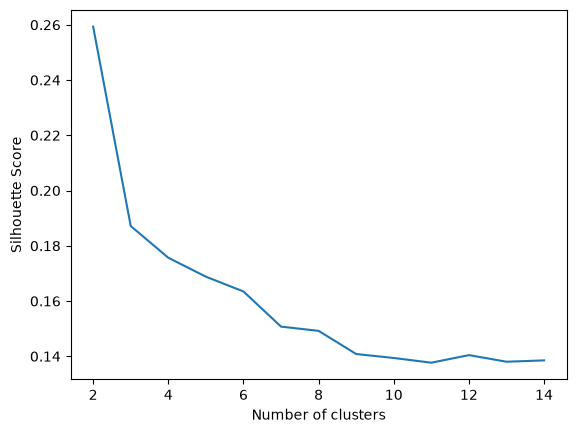

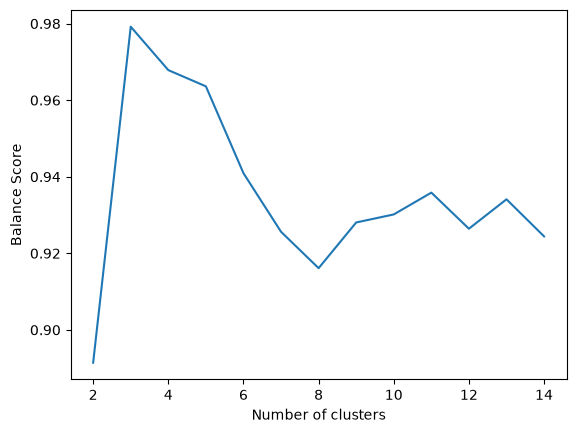

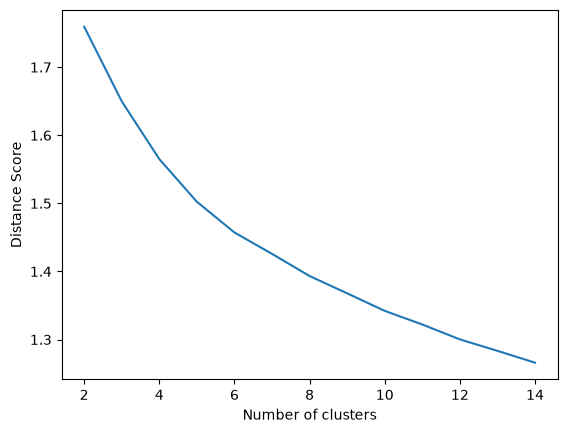

In [30]:
## Plot errors and pick how many cluster
cluster_counts = range(2, 15)

balance_scores = []
silhouette_scores = []
distance_scores = []

# My Note: Try cluster numbers range from 2 to 14, and calculate 3 different scores for each number of clusters.
# My Note: I tried to make cluster numbers range from 1-14, but the output went wrong. 
for num_clusters in cluster_counts:
    test_model = KMeans(n_clusters = num_clusters)
    test_predicted = test_model.fit_predict(ansur_features)
    balance_scores.append(balance_score(test_predicted))
    silhouette_scores.append(silhouette_score(ansur_features, test_predicted))
    distance_scores.append(distance_score(ansur_features, test_predicted))

# My Note: Then plot the data
plt.plot(cluster_counts,silhouette_scores)
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.show()

plt.plot(cluster_counts,balance_scores)
plt.xlabel("Number of clusters")
plt.ylabel("Balance Score")
plt.show()

plt.plot(cluster_counts,distance_scores)
plt.xlabel("Number of clusters")
plt.ylabel("Distance Score")
plt.show()


### Interpretation

<span style="color:hotpink;">
Based on the graphs of errors versus number of clusters, does it look like we should change the initial number of clusters ?<br>
How many clusters should we use ? Why ?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>
<br>
Yes, we should change the initial number of clusters. <br>
Looking at the graphs: the silhouette score is only good at small cluster numbers and flattens out before 8. The balance score is highest around 3-5 and drops at 8. And the distance score has its elbow around 5, it drops quickly before 5 and very slowly after. <br>
So 10 was too many, and I would use 5 clusters.<br>

### Revise Number of Clusters.

Re-run with the new number of clusters and plot the data in $2D$ or $3D$.

This can be the same graph as above.

balance_score: 0.9578125
silhouette_score: 0.16988930684515127
distance_score: 1.5019997200173116


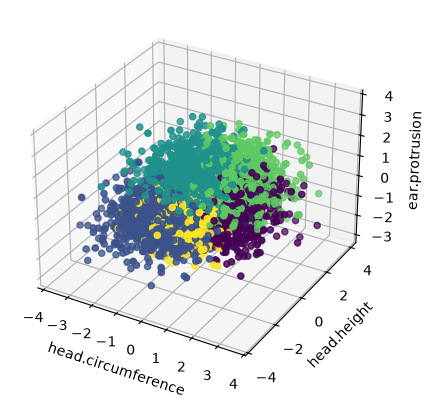

In [33]:
## Re-run clustering with final number of clusters
final_model = KMeans(n_clusters = 5)

## Run the model on the training data
final_predicted = final_model.fit_predict(ansur_features)

## Check errors
final_balance_score = balance_score(final_predicted)
final_silhouette_score = silhouette_score(ansur_features, final_predicted)
final_distance_score = distance_score(ansur_features, final_predicted)

# My Note: Show the final clustering scores in 3D plot.
print("balance_score:", final_balance_score)
print("silhouette_score:", final_silhouette_score)
print("distance_score:", final_distance_score)

## Plot in 3D
# My Note: Use Reference Documentation for 3D plotting with matplotlib. https://matplotlib.org/stable/gallery/mplot3d/scatter3d.html
fig = plt.figure()
axes = fig.add_subplot(projection ="3d")
axes.scatter(ansur_features["head.circumference"], ansur_features["head.height"], ansur_features["ear.protrusion"], c = final_predicted, cmap='viridis')
axes.set_xlabel("head.circumference")
axes.set_ylabel("head.height")
axes.set_zlabel("ear.protrusion")
plt.show()



### Interpretation

<span style="color:hotpink;">
Do these look better than the original number of clusters?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>
Yes, these plots looks better than the original one. <br>
With number 5 for clusters, both the balance score and the silhouette score improved compared to 10 clusters. <br>
Balance score: 0.958 > 0.945 <br>
Silhouette score: 0.170 > 0.141 <br>
The distance score is higher than the original one, which is: 1.502 > 1.339, which means the point density within single clustering group was looser than the original one. Thus the distance score still has space to improve.<br>

## Image Organization

We have a dataset of about $600$ flower images that we might want to classify by species... eventually.

What we want to do first is take a look at all of the images and see what kind of images we have, what kind of colors our flowers have and see if there's any other visual information that could help us classify these images later.

We'll see how to use clustering and distances to organize our images by color to create a visualization that we cna use to get to know our dataset.

### Load Dataset

The following cell downloads the dataset:

In [37]:
# !wget -qO- https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/flowers.tar.gz | tar xz

!curl -L -s -o flowers.tar.gz "https://github.com/PSAM-5020-2026F-A/5020-utils/releases/latest/download/flowers.tar.gz"
!tar -xzf flowers.tar.gz

Then, we can take a look at a few of the images:

In [38]:
IMG_DIR = "./data/image/flowers"

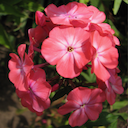

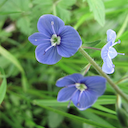

In [39]:
display(PImage.open(f"{IMG_DIR}/00_001.png"))
display(PImage.open(f"{IMG_DIR}/15_001.png"))

### Find Representative Colors

The overall process for organizing our images by color will be something like this:

1. Iterate over all files in the `data/image/flowers` directory, open each image file and treat it as a dataset
   1. Load image into a `DataFrame` where each pixel is a row and R,G,B values are columns/features
   2. Cluster into $2$ - $16$ colors
   3. Pick $3$ or $4$ representative colors
   4. Store image filenames and their representative colors in a Python object
2. Once all images have been processed we can order our dataset by different color characteristics: white to black, red to blue, hue value, brightness

### One Image

Let's step through the process of getting representative colors for one image, and then we can repeat this in a loop to process all of the flower images.

#### Open Image

The `PIL` library does all the work here:

In [40]:
# Open image
fname = "00_001.png"
pimg = PImage.open(f"{IMG_DIR}/{fname}").convert("RGB")

#### Put into `DataFrame`

We get the pixels and make a dataset/`DataFrame` out of them:

In [41]:
# Load into DataFrame
pxs = get_pixels(pimg)
pxs_df = pd.DataFrame(pxs, columns=["R", "G", "B"])

#### Cluster colors

Create a clustering object, cluster colors into $8$ clusters with `fit_predict()` and take a look at our color palette (`cluster_centers_`):

In [45]:
# TODO: Create Clustering object
color_model = KMeans(n_clusters = 8)

# TODO: Cluster by color
px_clusters = color_model.fit_predict(pxs_df)

# TODO: Take a look at the color palette (cluster_centers_)
print(color_model.cluster_centers_)


[[ 93.34203297  92.88873626  47.5157967 ]
 [243.09746328 117.98308856 140.63195372]
 [ 20.23752908  21.91005428  13.86120445]
 [165.92020202  48.23333333  66.62777778]
 [246.52578475 168.70964126 195.867713  ]
 [ 54.65458613  49.53914989  27.61700224]
 [119.18845585  30.60236803  40.70448939]
 [213.83134684  77.12991657  97.52920143]]


#### Checkpoint

<span style="color:hotpink;">
Does anything stand out about the colors?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

Yes. These numbers are not integers. And these 8 colors can be divided into 2 groups: <br>
A group of pinks/reds, and a group of dark greens/blacks. <br>
Which are matching the flower images presented above. <br>

#### Reconstruct Image

Since we're only doing one image for now, let's take a look at the clustering result.

This is like in the lecture notebook. We'll start with an empty pixel array and as we iterate through the `DataFrame` of cluster ids we append the corresponding colors to it.

In [48]:
# TODO: create empty pixel array
pxs_post = []

# TODO: iterate through resulting list of cluster ids
for cluster_id in px_clusters:
    # TODO: append corresponding color value to pixel array
    cluster_color = color_model.cluster_centers_[cluster_id]
    pxs_post.append([int(cluster_color[0]), int(cluster_color[1]), int(cluster_color[2])])
    

Now we can look at the image. If this next cell gives errors about using `float` values in images, just make sure the pixel values that are being appended above are all whole number `int` values.

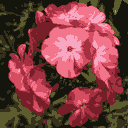

In [49]:
display(make_image(pxs_post, width=pimg.size[0]))

#### Checkpoint

<span style="color:hotpink;">
How does changing the number of clusters affect the resulting image?<br>Try some lower values like <code>2</code> and <code>4</code>, and also some higher ones like <code>12</code> and <code>16</code>. Take a look at a different image.
</span>

[[ 28.71895425  29.21023965  17.19716776]
 [243.68191654 131.34003091 155.09335394]
 [194.50916972  65.90530177  83.68756252]
 [108.05622576  53.82701422  44.35738906]]


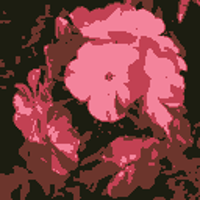

In [ ]:
# My Note: To make a comparison with 8 clusters, let's try 4 clusters.
color_model = KMeans(n_clusters = 4)
px_clusters = color_model.fit_predict(pxs_df)
print(color_model.cluster_centers_)

# TODO: create empty pixel array
pxs_post = []

# TODO: iterate through resulting list of cluster ids
for cluster_id in px_clusters:
    # TODO: append corresponding color value to pixel array
    cluster_color = color_model.cluster_centers_[cluster_id]
    pxs_post.append([int(cluster_color[0]), int(cluster_color[1]), int(cluster_color[2])])

# Display the reconstructed image in larger size.
display(make_image(pxs_post, width = pimg.size[0]).resize((200, 200)))

[[195.06630582  46.21786198  63.1217862 ]
 [ 67.28876509  68.3082637   33.42896936]
 [246.82481752 175.61605839 202.04963504]
 [245.65416354 131.21380345 156.19204801]
 [ 28.1206422   29.99266055  17.43440367]
 [130.48554337  42.62911266  58.57627119]
 [194.63636364  97.67084639 127.78369906]
 [108.62406639  25.27385892  32.38506224]
 [ 93.20245399  87.90593047  47.23517382]
 [ 11.55222222  13.36388889   9.92777778]
 [155.07462687  35.5807327   50.43147897]
 [219.42734123  74.1474704   93.15608181]
 [243.236      104.1736     123.9192    ]
 [164.61111111  64.45175439  87.22953216]
 [126.47395833 139.08854167  66.640625  ]
 [ 48.78397486  42.78790259  25.44854674]]


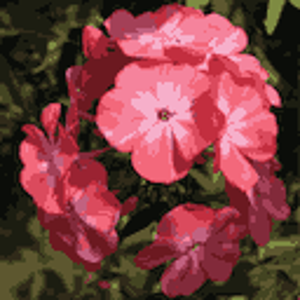

In [ ]:
# My Note: To make a comparison with 8 clusters and 4 clusters, let's try 16 clusters.
color_model = KMeans(n_clusters = 16)
px_clusters = color_model.fit_predict(pxs_df)
print(color_model.cluster_centers_)

# TODO: create empty pixel array
pxs_post = []

# TODO: iterate through resulting list of cluster ids
for cluster_id in px_clusters:
    # TODO: append corresponding color value to pixel array
    cluster_color = color_model.cluster_centers_[cluster_id]
    pxs_post.append([int(cluster_color[0]), int(cluster_color[1]), int(cluster_color[2])])

# Display the reconstructed image in larger size. (For better view of colors)
display(make_image(pxs_post, width = pimg.size[0]).resize((300, 300)))

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

I think the chapter "Find the Representative Colors, Reconstruct Colors" bring me back to Euclidean Distance Formula once again. It reminds me of calculating the distance between 2 cities on Earth, the Earth is a 3D sphere (It is not an 2D surface) thus we cannot simply use Pythagorean Theorem to calculate the distance. Instead, we need Euclidean Distance Formula to include their Cartesian coordinates, which can be reflected as RGB pixel values in 3D space in this example. <br>

The performance of having more clusters reminds me of observing neighboring RBG color pixels in 3D space. R, G, B can be seen as XYZ coordinates. If two colors are similar with each other, their color pixel coordinates are close together in 3D space. K-Means algorithm gathers neighboring coordinates into same cluster (group), a group can be seen as one kind of color family. 

Through the comparison between 4 clusters, 8 clusters and 16 clusters, we can see the number of clusters reflects how many color are shown in the reconstrcuted flower image. With 4 clusters, there are nearly only dominant colors for flowers shown in the image; with 8 clusters, there are balanced ratio of dominant colors for flowers, leaves and background; with 16 clusters, there are transition colors between neighboring areas.<br>

Thus, by using K-Means algorithm, with more clusters in image reconstruction, we can get more transition colors in visualized results, which make the image looks finer, smoother, and more realistic. <br>


#### Pick Colors

Ok, we have some representative colors for our images. We should keep more than one color, but maybe we don't have to keep $12$.

If we put our predictions in a `DataFrame` we can use the `value_counts()` function of our `DataFrame` to see how many pixels are represented by each of our cluster colors, and get the result ordered by most frequent to less frequent cluster id:

In [59]:
# cluster ids and pixel counts, ordered by descending counts
px_clusters_df = pd.DataFrame(px_clusters, columns=["clusters"])
ccounts = px_clusters_df["clusters"].value_counts()
display(ccounts)

clusters
4     2173
9     1800
3     1333
15    1278
12    1251
7     1197
1     1078
5     1011
8      980
11     929
0      739
10     737
13     685
2      685
6      318
14     190
Name: count, dtype: int64

Since what we are really trying to do here is get some information about the colors of the flowers present in our images, and given the type of images we have, we can start by assuming that the flower colors will be in the top-$4$ clusters returned by `value_counts()`.

We can revisit this assumption later. We might also want to add some filters here to ignore sky and vegetation colors (blues and greens) and only keep flower colors.

For now, let's just grab the top $4$ colors from `value_counts()`, remembering we want to keep their rounded `int` values and not the default `float` values in `cluster_centers_`.

In [ ]:
# Object to keep colors for each file
file_info = {
  "filename": fname,
  "colors": []
}

# TODO: go through ccounts.index and get corresponding colors for each clusters
# TODO: add top-4 colors to the "colors" key of the file_color_info object

for cluster_id in ccounts.index[:4]:
    cluster_color = color_model.cluster_centers_[cluster_id]
    file_info["colors"].append([int(cluster_color[0]), int(cluster_color[1]), int(cluster_color[2])])

In [62]:
display(file_info)

{'filename': '00_001.png',
 'colors': [[28, 29, 17], [11, 13, 9], [245, 131, 156], [48, 42, 25]]}

#### Checkpoint

<span style="color:hotpink;">
Why might we want to cluster into <code>8</code> or even <code>12</code> colors when in the end we're only keeping <code>4</code>?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

If we prioritize 4 clusters rather than more clusters, we will include every pixels of the image roughly into these 4 groups. Which means the clustering doesn't follow the pattern of color spectrum. If we want to draw specific color from large 4 clusters, it will be difficult. <br>

If we reconstruct image with 8 or more clusters, we will get smaller scale clusters that contains more accurate colors. Then we can pick 4 color from these clusters accordingly.

### Iterate and Cluster

We've processed one image, now let's process $600$... for-loops FTW!

We'll need to loop through all of the images in our directory and repeat the process above for each one of them.

We can create a function that takes a filename as input and returns the top-$4$ colors for that image, or... we can just put all of the clustering logic in the body of a for loop. Whichever is easiest.

Let's get started.

In [65]:
# list of all files in the flowers directory
flower_files = sorted([f for f in listdir(IMG_DIR) if f.endswith(".png")])

Here's the loop. In the end we want our `file_colors` list to have objects that have a filename and $4$ colors associated with each filename. Something like:

```py
[
  {
    "filename": "00_001.png",
    "colors": [[12,44,12], [112,144,62],  [12,84,112], [212,144,102]]
  },
  {
    "filename": "00_002.png",
    "colors": [[22,24,28], [112,114,122], [128,200,2], [250,240,230]]
  },
  ...
]
```

This can take a while to run (up to a minute for $600$ images). We can use slicing to test our logic on a subset of `flower_files` before processing all $600$ images.

In [ ]:
# List to keep colors for each file
file_colors = []

# TODO: get colors for each image
for fname in flower_files:
  # TODO: add logic here
  
  
  
  # TODO: add filename+colors object to list of objects
  file_colors.append({}) # Change this

#### Order Images (almost)

We have a list with objects that keep track of filenames and representative colors. We could create a `DataFrame` or csv dataset with these, but let's go ahead and just use this directly in this format.

What we want to do is re-order our list of objects, but using a `key` function that takes each object's colors into consideration.

We'll look into how to do this dynamically later, but for now let's order our images by something like _brightness_. It's _like_ brightness because what we'll do is measure how close each image is to the white color `(255,255,255)`.

We'll need some helper functions first:

- `color_distance()`: takes $2$ colors and returns the distance between them
- `min_color_distance()`: given a reference color and a list of colors, returns the distance between the reference color and the closest color in the list

In [ ]:
# TODO: implement function that returns distance between two colors
def color_distance(c0, c1):
  # TODO: add logic here
  return 0 # TODO: Change this

Some tests for the `color_distance()` function:

In [ ]:
# Some tests for the color_distance() function
print(color_distance([0,0,0], [255,255,255]), "should be", 255*3**.5)
print(color_distance([0,100,0], [100,100,0]), "should be", 100)
print(color_distance([55,222,120], [91,51,192]), "should be", 189)
print(color_distance([147,207,246], [87,57,50]), "should be", 254)
print(color_distance([12,250,126], [112,10,195]), "should be", 269)
print(color_distance([106,71,61], [105,136,100]), "should be", 75.81)

In [ ]:
# TODO: implement function that returns minimum distance between a reference color and colors from a list
def min_color_distance(ref_color, color_list):
  # TODO: add logic here
  return 0 # TODO: Change this

Three tests for the `min_color_distance()` function:

In [ ]:
# Some tests for the color_distance() function
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,58,58]]), "should be", 100)
print(min_color_distance([0,0,0], [[255,255,255],[0,100,0],[100,100,0],[58,57,58]]), "should be", 99.88)
print(min_color_distance([91,51,192], [[147,207,246],[87,57,50],[12,250,126],[112,10,195]]), "should be", 46.16)

#### Order Images (for real now)

Alright. We have a function that can be used to order our images by their distance to a given color.

Let's order our images by how close they are to the brightest color `(255,255,255)`. We'll define a `key` function that, given an object from our `file_colors` list, returns how close that image is to the color `(255,255,255)`.

In [ ]:
# TODO: implement function that returns how close our image is to the color white
def by_bright_dist(A):
  # TODO: add logic here
  return 0 # TODO: Change this

Order the list and write out a `JSON` file with the image order.

In [ ]:
file_colors_sorted = sorted(file_colors, key=by_bright_dist)

In [ ]:
files_sorted = [A["filename"] for A in file_colors_sorted]

with open("./data/flower_order.json", "w") as ofp:
  json.dump(files_sorted, ofp)

### Viewing Results

We can check the results by running a webserver and looking at a simple web page that orders the images according to the resulting `JSON` file from above.

We'll make use of the [`Live Server`](https://marketplace.visualstudio.com/items?itemName=ritwickdey.LiveServer) VSCode extension.

We can start the server by clicking on the "_Go Live_" button towards the right hand side of the bar at the very bottom of our text editor:

<img src="https://psam-5020-2026f-a.github.io/5020-imgs/HW09/go_live.jpg" width="600px">

Clicking the "_Go Live_" button in Codespace should open up a new tab with a plain html navigation view of our repository. Clicking on the `html/` directory should open up a web page with all of the flower images. If not, you can use your Codespace url to try to find the web server address.

If your Codespace url is something like:<br>`https://mango-special-giggle-v6v7asd322f7p6.github.dev/`

Then, the webserver should be running at:<br>`https://mango-special-giggle-v6v7asd322f7p6-5500.app.github.dev/`

### Review, Contemplate, Experiment

Yes, images with white parts are towards the beginning, but the images towards the end aren't necessarily the ones with dark flowers, but are the ones that have all of their representative colors farthest away from white `(255,255,255)`, which includes very saturated colors/images.

A couple of interesting experiments here could be:
- Decrease the number of clusters or the number of colors kept after clustering.
- Use different colors as the reference for the distance functions. For example, create `by_gold_dist()` or `by_purple_dist()` functions to use as the `key` for sorting.
- Order the list of cluster colors by [hue](https://stackoverflow.com/questions/23090019/fastest-formula-to-get-hue-from-rgb). This can be a bit tricky to get right because some colors, like white, black and gray, don't have a unique value for hue, but depend on other aspects of the color, like saturation and lightness, to be well-defined.

In [ ]:
# TODO: experiment with number of clusters, number of colors, reference colors or hue distances

### Interpretation

<span style="color:hotpink;">
What did you try ? What happened ?
</span>

<span style="color:hotpink;">EDIT THIS CELL WITH ANSWER</span>

### Conclusion

It's challenging to define a set of functions that will perfectly order our flowers by color without first having to define very specific color values for filtering and corner-cases. At a high-level, we can imagine that this is because color is a $3$-dimensional value, and we're using it to organize our images into a single-dimensional order.

The beginning of our ordering is usually pretty good, since there's only one way for a color to be _close_ to our reference color, but the ordering gets less consistent towards the end because there are many different ways for a color to be _far_ from the reference color.

Next week we'll see a very powerful technique that, amongst other things, will help us get around this kind of "_dimensionality mismatch_".